# Mendeteksi URL Phishing: Apa yang Sebenarnya Dipelajari Model?

| | |
| --- | --- |
| **Kompetisi** | [Data Science Olympiads (DSCO) 2025](https://www.kaggle.com/competitions/dsco) (Data Science Club, Kaggle, November–Desember 2025) |
| **Tujuan** | Membedakan URL *legitimate* (1) dan *phishing* (0) dari string URL dan 16 fitur leksikal (metrik ROC AUC) |
| **Data** | 80.974 URL berlabel dan 20.244 URL uji, turunan dataset LegitPhish |
| **Penulis** | Fauzan Ahsanudin Alfikri · [Kaggle: fauzan2](https://www.kaggle.com/fauzan2) |
| **Tanggal** | Disusun ulang November 2026, menggantikan notebook kompetisi Desember 2025 |
| **Lingkungan** | Dijalankan penuh di Kaggle (CPU) |

**Pertanyaan penelitian.** Skor AUC di atas 0,99 mudah dicapai di kompetisi ini. Apakah itu berarti model memahami
phishing, atau hanya mengenali cara dataset ini disusun?

**Ringkasan temuan.**
- Dataset ini didominasi dua tipe URL: **host berupa alamat IP** (48,5%, hanya 3,3% legitimate) dan **beranda polos `https://www.<domain>`** (36,5%, 96,6% legitimate). Aturan satu baris "beranda = legitimate" sudah mencapai AUC 0,959.
- Sekitar 56% baris punya minimal satu fitur bawaan yang tidak cocok dengan string URL-nya (entropi, panjang path, persen digit, jumlah token). Nilai yang diubah ini justru membawa informasi tambahan: di dalam URL host IP, entropi bawaan memisahkan label dengan AUC 0,90, sedangkan entropi yang dihitung ulang dari URL hanya 0,83.
- LightGBM pada fitur bawaan plus 20 fitur yang dihitung ulang dari URL mencapai **AUC OOF 0,9933**. Model yang hanya memakai fitur bersih dari URL mencapai 0,9876.
- **92% kesalahan model** berasal dari dua kelompok kecil: host IP berlabel legitimate (1.299 URL, contoh `http://59.89.186.229:59571/bin.sh`) dan beranda berlabel phishing (1.017 URL). Label ini berlawanan dengan isi URL-nya dan kemungkinan besar keliru.
- Late submission: public **0,99399**, private **0,99390**, di atas submission tim terbaik saat kompetisi (private 0,99378, peringkat akhir 24 dari 90) dan 0,0002 di bawah peringkat 1 (0,99410).

**Alur:** 1. Setup → 2. Memahami data → 3. EDA → 4. Preprocessing → 5. Baseline → 6. Model →
7. Interpretasi dan analisis error → 8. Submission → 9. Kesimpulan

## 1. Setup

Semua import, parameter, dan path ada di sel ini. Fitur yang dihitung ulang dari URL ada di `src/features`, dan
cross-validation ada di `src/models`.

In [1]:
import os
import shutil
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict

SRC_ROOT = Path.cwd().parent
for r, _, f in os.walk("/kaggle/input", followlinks=True):
    if Path(r).name == "features" and "url_features.py" in f:
        pkg = Path(r).parent
        if pkg.name == "src":
            SRC_ROOT = pkg.parent
        else:
            SRC_ROOT = Path("/tmp/project")
            shutil.copytree(pkg, SRC_ROOT / "src", dirs_exist_ok=True)
        break
sys.path.insert(0, str(SRC_ROOT))
from src.data.load_data import ID, PROVIDED, TARGET, find_data_dir, load
from src.features.url_features import mismatch, recompute, url_type
from src.models.train_model import auc_by_seed, cv_predict, lgb_model, logreg_model, rank_mean, tfidf_model
from src.visualization.plots import PALETTE, pct_axis, save_fig, set_style

# ── Parameter eksperimen
SEEDS = range(3)                 # Stratified 5-Fold diulang dengan 3 seed

# ── Path
DATA_DIR = find_data_dir(local="../data/raw")
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../reports")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
set_style()
C1, C2, C3, CN = PALETTE["normal"], PALETTE["fraud"], PALETTE["accent"], PALETTE["neutral"]
T0 = time.time()
print("DATA_DIR:", DATA_DIR, "| OUT_DIR:", OUT_DIR)

DATA_DIR: /kaggle/input/datasets/fauzan2/dsco-2025-phishing-data | OUT_DIR: /kaggle/working


## 2. Memahami data

Setiap baris adalah satu URL beserta 16 fitur leksikal yang sudah dihitung penyelenggara: panjang URL, jumlah titik,
entropi, jumlah token, panjang path, jumlah digit, dan seterusnya. Label `ClassLabel` bernilai 1 untuk URL legitimate dan
0 untuk phishing.

In [2]:
train, test, sample = load(DATA_DIR)
y = train[TARGET].values
print(f"Train: {train.shape} | Test: {test.shape} | nilai kosong train/test: {train.isna().sum().sum()}/{test.isna().sum().sum()}")
print(f"Legitimate: {y.mean():.1%} | URL duplikat di train: {train.URL.duplicated().sum()} | URL test yang juga ada di train: {test.URL.isin(train.URL).mean():.2%}")
pd.concat([train[train[TARGET] == k].sample(5, random_state=1)[["URL", TARGET]] for k in [1, 0]], ignore_index=True)

Train: (80974, 18) | Test: (20244, 18) | nilai kosong train/test: 0/0
Legitimate: 37.6% | URL duplikat di train: 219 | URL test yang juga ada di train: 0.58%


,URL,ClassLabel
0,https://www.egalitarianpublishing.com,1
1,https://www.researchinformation.info,1
2,https://www.tipro.org,1
3,https://www.business-sweden.com,1
4,https://www.gallimard.fr,1
5,http://117.221.113.155:38110/i,0
6,http://bot.haluodq.cc/main_mips,0
7,http://182.113.47.220:54538/i,0
8,http://jask.powerforxes.shop/prog/66e9095f50a8...,0
9,http://207.244.199.140/hiddenbin/boatnet.arm5,0


**Temuan.** 80.974 URL berlabel tanpa nilai kosong, 37,6% legitimate. Contoh di atas sudah memperlihatkan pola utamanya: URL legitimate hampir semuanya beranda situs dengan `https://www.`, sedangkan URL phishing banyak berupa alamat IP dengan port dan file seperti `/i`, `/bin.sh`, atau `.arm5`. Hanya 0,58% URL test yang juga muncul di train, jadi menghafal URL tidak membantu.

## 3. Exploratory Data Analysis

### 3.1 Dua tipe URL mendominasi dataset

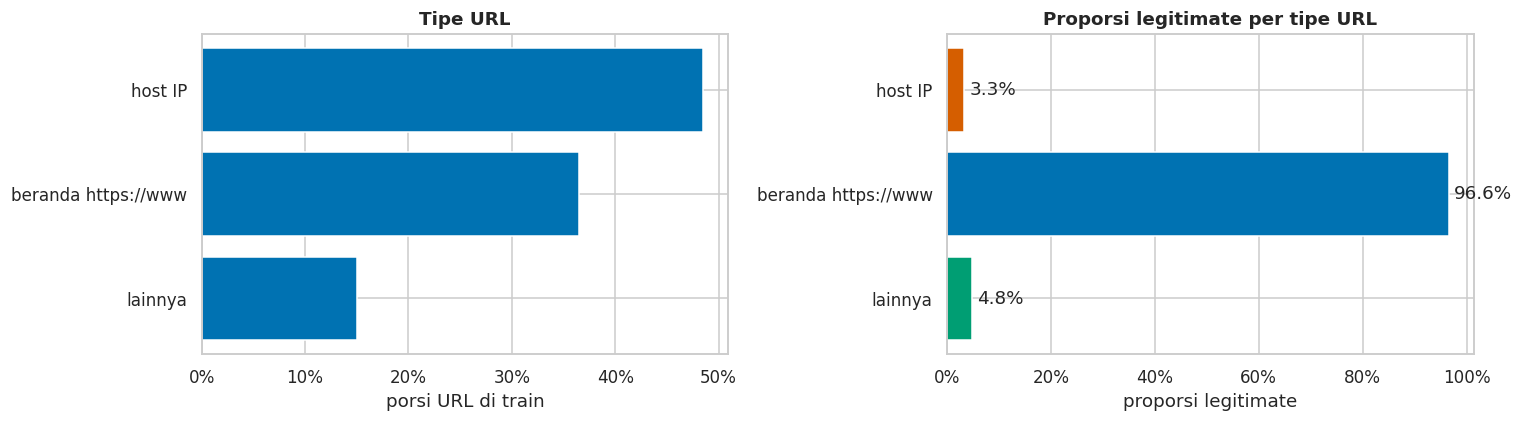

AUC aturan 'beranda https://www = legitimate': 0.9591


,porsi train,porsi test,proporsi legit,jumlah
host IP,48.5%,48.3%,3.3%,"39,278"
beranda https://www,36.5%,36.6%,96.6%,"29,563"
lainnya,15.0%,15.1%,4.8%,"12,133"


In [3]:
TYPE_TR, TYPE_TE = url_type(train.URL), url_type(test.URL)
ORDER = ["host IP", "beranda https://www", "lainnya"]
tt = pd.DataFrame({"porsi train": TYPE_TR.value_counts(normalize=True), "porsi test": TYPE_TE.value_counts(normalize=True),
                   "proporsi legit": train.groupby(TYPE_TR)[TARGET].mean(), "jumlah": TYPE_TR.value_counts()}).loc[ORDER]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(ORDER[::-1], tt["porsi train"][::-1], color=C1)
pct_axis(ax[0], 0, axis="x"); ax[0].set(xlabel="porsi URL di train", title="Tipe URL")
ax[1].barh(ORDER[::-1], tt["proporsi legit"][::-1], color=[C3, C1, C2])
pct_axis(ax[1], 0, axis="x"); ax[1].set(xlabel="proporsi legitimate", title="Proporsi legitimate per tipe URL")
for i, v in enumerate(tt["proporsi legit"][::-1]):
    ax[1].text(v + 0.01, i, f"{v:.1%}", va="center")
save_fig(FIG_DIR, "01_url_types")
rule_auc = roc_auc_score(y, (TYPE_TR == "beranda https://www").astype(int))
print(f"AUC aturan 'beranda https://www = legitimate': {rule_auc:.4f}")
tt.style.format({"porsi train": "{:.1%}", "porsi test": "{:.1%}", "proporsi legit": "{:.1%}", "jumlah": "{:,.0f}"})

**Temuan.** Dua tipe URL menjelaskan 85% data dan hampir seluruh label: host IP 96,7% phishing, beranda `https://www` 96,6% legitimate. Sisanya (15%) sebagian besar phishing (4,8% legitimate). Porsi tiap tipe di test sama persis dengan train. Aturan "beranda = legitimate" saja memberi AUC 0,959, sehingga sebagian besar pekerjaan model sebenarnya adalah mengenali struktur ini.

### 3.2 Fitur bawaan per kelas

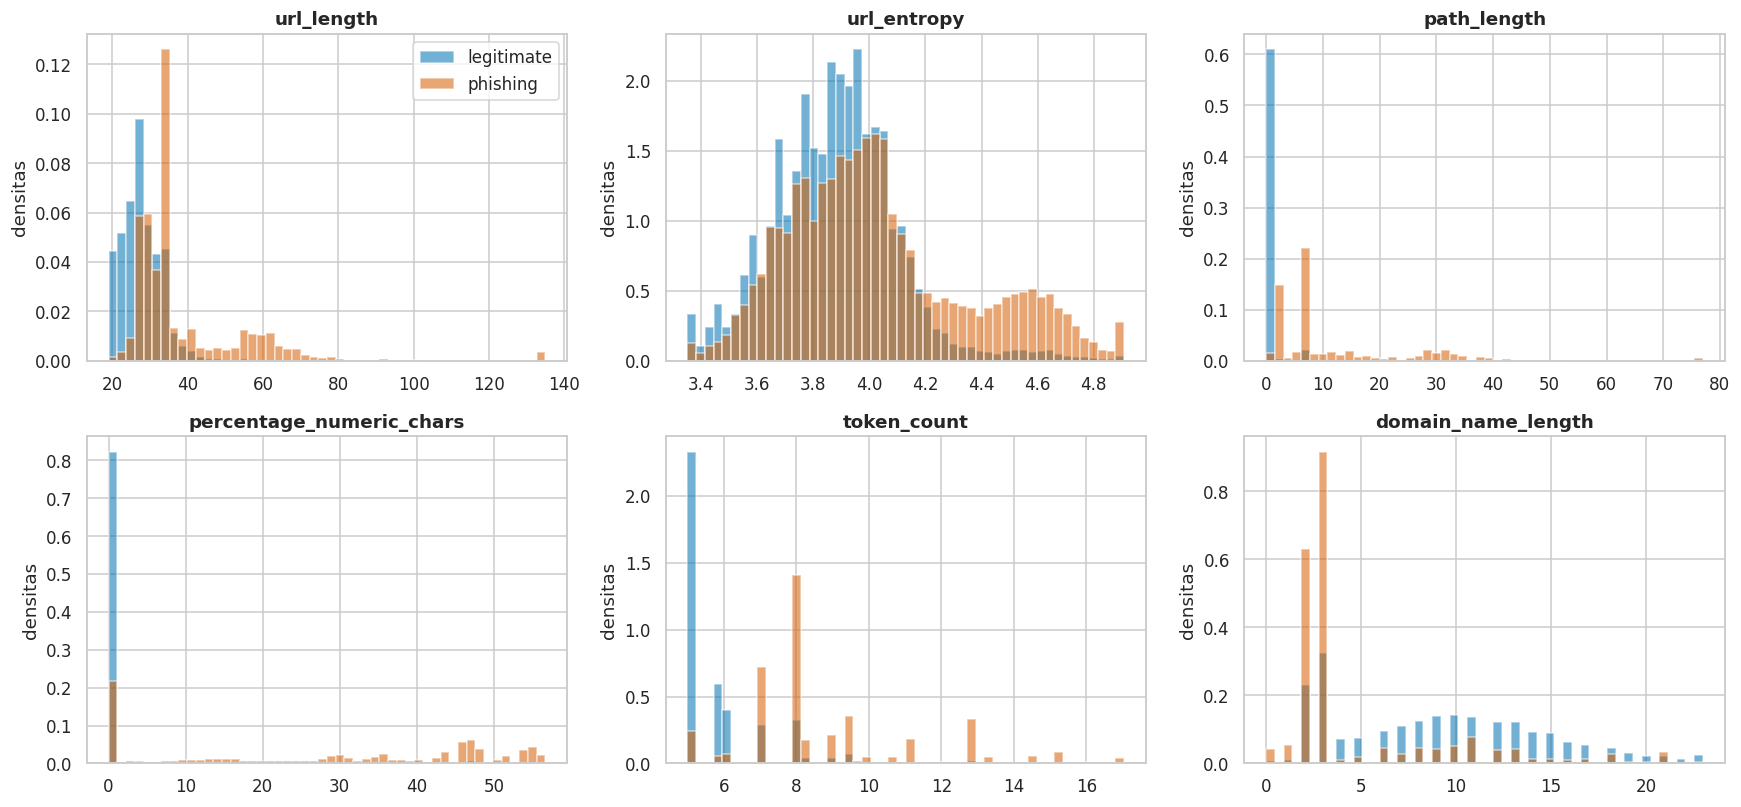

,AUC satu fitur
path_length,0.957
number_of_digits,0.944
percentage_numeric_chars,0.943
https_flag,0.939
dot_count,0.891
token_count,0.879
has_ip_address,0.855
url_length,0.805


In [4]:
show = ["url_length", "url_entropy", "path_length", "percentage_numeric_chars", "token_count", "domain_name_length"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for a, c in zip(axes.flat, show):
    lo, hi = train[c].quantile([0.005, 0.995])
    for k, col, lab in [(1, C1, "legitimate"), (0, C2, "phishing")]:
        a.hist(train.loc[train[TARGET] == k, c].clip(lo, hi), bins=50, alpha=0.55, density=True, color=col, label=lab)
    a.set(title=c, ylabel="densitas")
axes[0, 0].legend()
save_fig(FIG_DIR, "02_provided_features")
single = pd.Series({c: max(roc_auc_score(y, train[c]), 1 - roc_auc_score(y, train[c])) for c in PROVIDED}).sort_values(ascending=False)
single.head(8).to_frame("AUC satu fitur").style.format("{:.3f}")

**Temuan.** Fitur bawaan yang paling memisahkan kelas sendirian adalah panjang path (AUC 0,957), jumlah digit (0,944), persen digit (0,943), dan flag HTTPS (0,939). Semuanya adalah cara lain untuk mengatakan "beranda https polos atau bukan": beranda tidak punya path, tidak punya digit, dan memakai HTTPS.

### 3.3 Apakah fitur bawaan sesuai dengan URL-nya?

Sebagian besar fitur bisa dihitung ulang langsung dari string URL. Jika fitur bawaan tidak sama dengan hasil hitung ulang,
berarti nilainya diubah oleh penyusun data.

Cocok persis dengan hasil hitung ulang: url_length 1.0 | number_of_digits 1.0 | dot_count 1.0


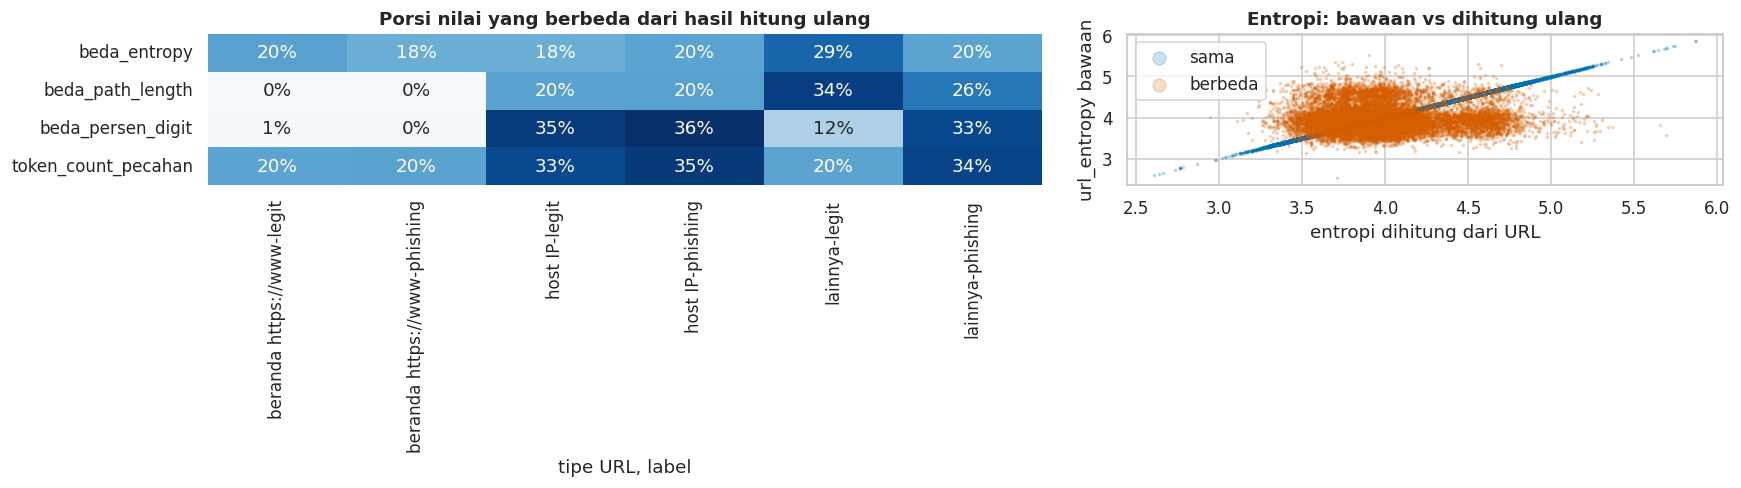

Porsi baris dengan minimal satu nilai berbeda: train 0.563 | test 0.56


In [5]:
CLEAN_TR, CLEAN_TE = recompute(train.URL), recompute(test.URL)
MIS_TR, MIS_TE = mismatch(train, CLEAN_TR), mismatch(test, CLEAN_TE)
print("Cocok persis dengan hasil hitung ulang: url_length", np.mean(train.url_length == CLEAN_TR.u_len).round(3),
      "| number_of_digits", np.mean(train.number_of_digits == CLEAN_TR.u_digits).round(3),
      "| dot_count", np.mean(train.dot_count == train.URL.str.count(r"\.")).round(3))
rate = MIS_TR.groupby([TYPE_TR, train[TARGET].map({1: "legit", 0: "phishing"})]).mean().T
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(rate[[c for c in rate.columns if c[0] in ORDER]], annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax[0])
ax[0].set(xlabel="tipe URL, label", ylabel="", title="Porsi nilai yang berbeda dari hasil hitung ulang")
m = MIS_TR.beda_entropy == 1
ax[1].scatter(CLEAN_TR.u_entropy[~m], train.url_entropy[~m], s=2, alpha=0.2, color=C1, label="sama")
ax[1].scatter(CLEAN_TR.u_entropy[m], train.url_entropy[m], s=2, alpha=0.2, color=C2, label="berbeda")
ax[1].set(xlabel="entropi dihitung dari URL", ylabel="url_entropy bawaan", title="Entropi: bawaan vs dihitung ulang"); ax[1].legend(markerscale=6)
save_fig(FIG_DIR, "03_feature_noise")
print("Porsi baris dengan minimal satu nilai berbeda: train", (MIS_TR.sum(1) > 0).mean().round(3), "| test", (MIS_TE.sum(1) > 0).mean().round(3))

**Temuan.** Panjang URL, jumlah digit, dan jumlah titik cocok 100% dengan string URL. Namun entropi, panjang path, persen digit, dan jumlah token berbeda di 14–29% baris, dan 56% baris punya minimal satu nilai yang berbeda, di train maupun test. Heatmap menunjukkan porsinya hampir sama untuk label legitimate dan phishing di dalam tipe URL yang sama, jadi nilai-nilai ini tidak diubah berdasarkan label secara langsung. Grafik kanan memperlihatkan bentuk perubahannya: entropi yang diubah tersebar acak di sekitar nilai aslinya. Ini tanda bahwa penyusun data menyisipkan noise ke sebagian fitur.

### 3.4 Label yang berlawanan dengan tipe URL-nya

In [6]:
odd_ip = (TYPE_TR == "host IP") & (train[TARGET] == 1)
odd_home = (TYPE_TR == "beranda https://www") & (train[TARGET] == 0)
print(f"Host IP berlabel legitimate: {odd_ip.sum():,} ({odd_ip.sum() / (TYPE_TR == 'host IP').sum():.1%} dari host IP)")
print(f"Beranda https://www berlabel phishing: {odd_home.sum():,} ({odd_home.sum() / (TYPE_TR == 'beranda https://www').sum():.1%} dari beranda)")
dups = train[train.URL.duplicated(keep=False)].groupby("URL")[TARGET].nunique()
print(f"URL duplikat dengan label berbeda: {(dups > 1).sum()} dari {len(dups)}")
# Di dalam host IP: seberapa bisa label dibedakan oleh entropi bawaan vs entropi yang dihitung ulang?
ipm = (TYPE_TR == "host IP").values
cv = StratifiedKFold(5, shuffle=True, random_state=0)
ent_auc = {}
for name, col in [("url_entropy bawaan", train.url_entropy), ("entropi dihitung dari URL", CLEAN_TR.u_entropy)]:
    p = cross_val_predict(lgb_model(0, n_estimators=200), col[ipm].to_frame(), y[ipm], cv=cv, method="predict_proba")[:, 1]
    ent_auc[name] = roc_auc_score(y[ipm], p)
print("AUC di dalam host IP, satu fitur:", {k: round(v, 3) for k, v in ent_auc.items()})
pd.DataFrame({"host IP berlabel legitimate": train.URL[odd_ip].sample(6, random_state=0).values,
              "beranda berlabel phishing": train.URL[odd_home].sample(6, random_state=0).values})

Host IP berlabel legitimate: 1,299 (3.3% dari host IP)
Beranda https://www berlabel phishing: 1,017 (3.4% dari beranda)
URL duplikat dengan label berbeda: 13 dari 201
AUC di dalam host IP, satu fitur: {'url_entropy bawaan': np.float64(0.902), 'entropi dihitung dari URL': np.float64(0.825)}


,host IP berlabel legitimate,beranda berlabel phishing
0,http://103.197.115.101:47166/Mozi.m,https://www.thecountrywillows.com
1,http://38.242.132.137/mipsel,https://www.coolest-gadgets.com
2,http://59.89.186.229:59571/bin.sh,https://www.millerhomerenovations.net
3,http://115.50.3.176:42561/bin.sh,https://www.goiasec.com.br
4,http://8.140.198.73:3333/i,https://www.karpassociatesinc.com
5,http://45.115.89.117:56821/Mozi.m,https://www.olyrix.com


**Temuan.** 1.299 URL host IP (3,3%) berlabel legitimate, padahal bentuknya sama dengan malware lain, misalnya `http://59.89.186.229:59571/bin.sh`. Sebaliknya, 1.017 beranda biasa (3,4%) berlabel phishing. Ada juga 13 URL duplikat dengan label berbeda. Label-label ini kemungkinan besar keliru. Hal yang menarik: di dalam host IP, entropi **bawaan** memisahkan label dengan AUC 0,90, lebih tinggi dari entropi yang dihitung dari URL (0,83). Artinya noise yang disisipkan ikut membawa jejak label, dan model bisa memanfaatkannya tanpa memahami URL-nya.

### 3.5 Apakah test berasal dari distribusi yang sama?

In [7]:
adv_X = pd.concat([train[PROVIDED], test[PROVIDED]], ignore_index=True)
adv_y = np.r_[np.zeros(len(train)), np.ones(len(test))]
adv_p = cross_val_predict(lgb_model(0, n_estimators=200), adv_X, adv_y, cv=cv, method="predict_proba")[:, 1]
print(f"Adversarial validation AUC train vs test: {roc_auc_score(adv_y, adv_p):.3f}")

Adversarial validation AUC train vs test: 0.498


**Temuan.** AUC 0,498, praktis acak. Train dan test disusun dengan cara yang sama, termasuk noise pada fitur, sehingga skor cross-validation layak dipercaya untuk test.

## 4. Preprocessing

Keputusan yang diambil dari EDA:

- **Fitur bawaan dipakai apa adanya**, karena kompetisi menilai prediksi pada data yang disusun dengan cara yang sama.
- **Fitur bersih dihitung ulang dari URL** (20 fitur: panjang host, kedalaman path, port, jumlah huruf besar, ekstensi
  berisiko, entropi asli, dan lain-lain). Model yang hanya memakai fitur bersih menunjukkan seberapa jauh kita bisa tanpa
  bergantung pada nilai yang diubah penyusun data.
- **Penanda perbedaan** (4 kolom) disiapkan untuk diuji, bukan langsung dipakai.
- **String URL** dipakai langsung oleh model teks TF-IDF karakter 2–5.

In [8]:
X_prov, X_clean = train[PROVIDED], CLEAN_TR
X_both = pd.concat([train[PROVIDED], CLEAN_TR], axis=1)
X_all = pd.concat([X_both, MIS_TR], axis=1)
print({k: v.shape[1] for k, v in {"bawaan": X_prov, "bersih": X_clean, "bawaan + bersih": X_both, "+ penanda": X_all}.items()})
RESULTS, OOF = {}, {}

def record(name, oof):
    s = auc_by_seed(oof, y)
    OOF[name] = np.atleast_2d(oof).mean(0)
    RESULTS[name] = {"AUC OOF": np.mean(s), "std antar seed": np.std(s)}
    return f"{name}: AUC {np.mean(s):.5f} ± {np.std(s):.5f}"

{'bawaan': 16, 'bersih': 20, 'bawaan + bersih': 36, '+ penanda': 40}


## 5. Baseline

Semua skor adalah AUC out-of-fold dari Stratified 5-Fold yang diulang dengan 3 seed. Baseline: aturan satu baris dari
bagian 3.1, dan regresi logistik pada 16 fitur bawaan.

In [9]:
print(record("aturan beranda https://www", np.tile((TYPE_TR == "beranda https://www").astype(float).values, (len(SEEDS), 1))))
print(record("regresi logistik, fitur bawaan", cv_predict(logreg_model, X_prov, y, SEEDS)))

aturan beranda https://www: AUC 0.95908 ± 0.00000
regresi logistik, fitur bawaan: AUC 0.97120 ± 0.00002


**Temuan.** Aturan beranda memberi AUC 0,9591, dan regresi logistik pada 16 fitur bawaan menaikkannya ke 0,9712. Batas antara kedua kelas tidak linear: kombinasi seperti "host IP tanpa path" atau "beranda dengan digit" butuh model berbasis pohon.

## 6. Model

LightGBM pada empat set fitur, model teks TF-IDF pada string URL, dan rata-rata peringkat keduanya.

In [10]:
t = time.time()
for name, X in [("LightGBM, fitur bersih dari URL", X_clean), ("LightGBM, fitur bawaan", X_prov),
                ("LightGBM, bawaan + bersih", X_both), ("LightGBM, bawaan + bersih + penanda", X_all)]:
    print(record(name, cv_predict(lgb_model, X, y, SEEDS)), f"({(time.time() - t) / 60:.1f} menit)")
print(record("TF-IDF karakter + regresi logistik", cv_predict(tfidf_model, train.URL, y, SEEDS)), f"({(time.time() - t) / 60:.1f} menit)")
OOF["rata-rata peringkat: LightGBM bawaan + bersih & TF-IDF"] = rank_mean(OOF["LightGBM, bawaan + bersih"], OOF["TF-IDF karakter + regresi logistik"])
RESULTS["rata-rata peringkat: LightGBM bawaan + bersih & TF-IDF"] = {"AUC OOF": roc_auc_score(y, OOF["rata-rata peringkat: LightGBM bawaan + bersih & TF-IDF"]), "std antar seed": np.nan}

LightGBM, fitur bersih dari URL: AUC 0.98755 ± 0.00009 (0.9 menit)
LightGBM, fitur bawaan: AUC 0.99309 ± 0.00004 (1.6 menit)
LightGBM, bawaan + bersih: AUC 0.99326 ± 0.00005 (2.6 menit)
LightGBM, bawaan + bersih + penanda: AUC 0.99327 ± 0.00005 (3.5 menit)
TF-IDF karakter + regresi logistik: AUC 0.97513 ± 0.00016 (7.7 menit)


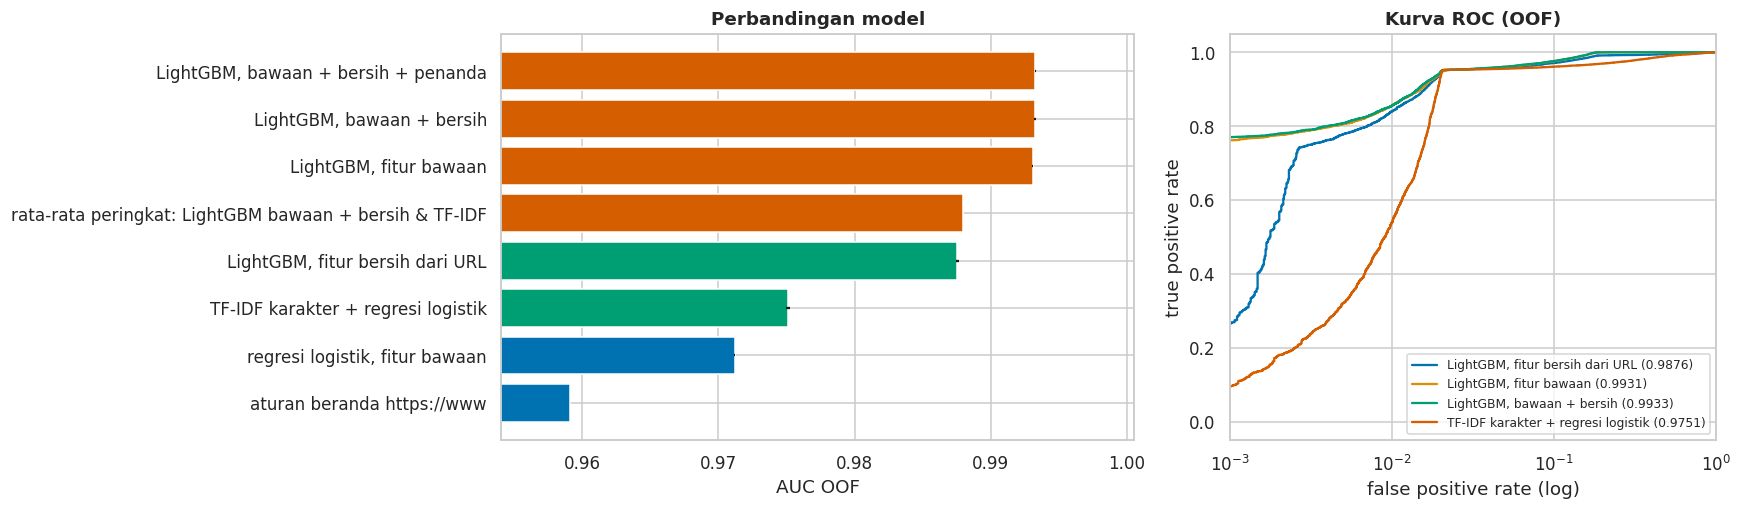

,AUC OOF,std antar seed
aturan beranda https://www,0.95908,0.00000
"regresi logistik, fitur bawaan",0.97120,0.00002
TF-IDF karakter + regresi logistik,0.97513,0.00016
"LightGBM, fitur bersih dari URL",0.98755,0.00009
rata-rata peringkat: LightGBM bawaan + bersih & TF-IDF,0.98798,nan
"LightGBM, fitur bawaan",0.99309,0.00004
"LightGBM, bawaan + bersih",0.99326,0.00005
"LightGBM, bawaan + bersih + penanda",0.99327,0.00005


In [11]:
res = pd.DataFrame(RESULTS).T.sort_values("AUC OOF")
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
cols = [C2 if "bawaan" in n and "LightGBM" in n else (C3 if "bersih dari URL" in n or "TF-IDF" in n else C1) for n in res.index]
ax[0].barh(res.index, res["AUC OOF"], xerr=res["std antar seed"].fillna(0), color=cols)
ax[0].set_xlim(res["AUC OOF"].min() - 0.005, 1.0005); ax[0].set(xlabel="AUC OOF", title="Perbandingan model")
for n in ["LightGBM, fitur bersih dari URL", "LightGBM, fitur bawaan", "LightGBM, bawaan + bersih", "TF-IDF karakter + regresi logistik"]:
    fpr, tpr, _ = roc_curve(y, OOF[n])
    ax[1].plot(fpr, tpr, label=f"{n} ({RESULTS[n]['AUC OOF']:.4f})")
ax[1].set(xscale="log", xlim=(1e-3, 1), xlabel="false positive rate (log)", ylabel="true positive rate", title="Kurva ROC (OOF)")
ax[1].legend(fontsize=8, loc="lower right")
save_fig(FIG_DIR, "04_model_comparison")
res.style.format({"AUC OOF": "{:.5f}", "std antar seed": "{:.5f}"})

**Temuan.** LightGBM pada fitur bawaan mencapai 0,99309. Menambahkan fitur yang dihitung ulang dari URL menaikkannya sedikit ke 0,99326, dan penanda perbedaan tidak menambah apa pun (0,99327). Model yang **hanya** memakai fitur bersih dari URL mencapai 0,98755, lebih rendah 0,006 dari model dengan fitur bawaan; selisih ini adalah nilai informasi yang dibawa fitur yang sudah diubah. Model teks TF-IDF karakter (0,975) kalah dari model fitur, dan rata-rata peringkatnya dengan LightGBM malah menurunkan skor (0,988). Variasi antar seed sangat kecil (±0,00005) untuk semua model LightGBM.

### 6.1 Model akhir

Model dipilih dengan aturan parsimoni: model paling sederhana yang AUC-nya tidak lebih buruk dari model terbaik lebih dari
dua standar deviasi antar seed. Urutan kesederhanaan: LightGBM fitur bawaan, bawaan + bersih, + penanda, lalu
rata-rata peringkat dengan TF-IDF.

In [12]:
best = res["AUC OOF"].idxmax()
tol = 2 * np.nanmax([res.loc[best, "std antar seed"], 1e-5])
candidates = ["LightGBM, fitur bawaan", "LightGBM, bawaan + bersih", "LightGBM, bawaan + bersih + penanda",
              "rata-rata peringkat: LightGBM bawaan + bersih & TF-IDF"]
FINAL_NAME = next(n for n in candidates if res.loc[n, "AUC OOF"] >= res.loc[best, "AUC OOF"] - tol)
print(f"Terbaik: {best} ({res.loc[best, 'AUC OOF']:.5f}) | Model akhir: {FINAL_NAME} ({res.loc[FINAL_NAME, 'AUC OOF']:.5f})")

Terbaik: LightGBM, bawaan + bersih + penanda (0.99327) | Model akhir: LightGBM, bawaan + bersih (0.99326)


## 7. Interpretasi dan analisis error

### 7.1 Fitur apa yang dipakai model?

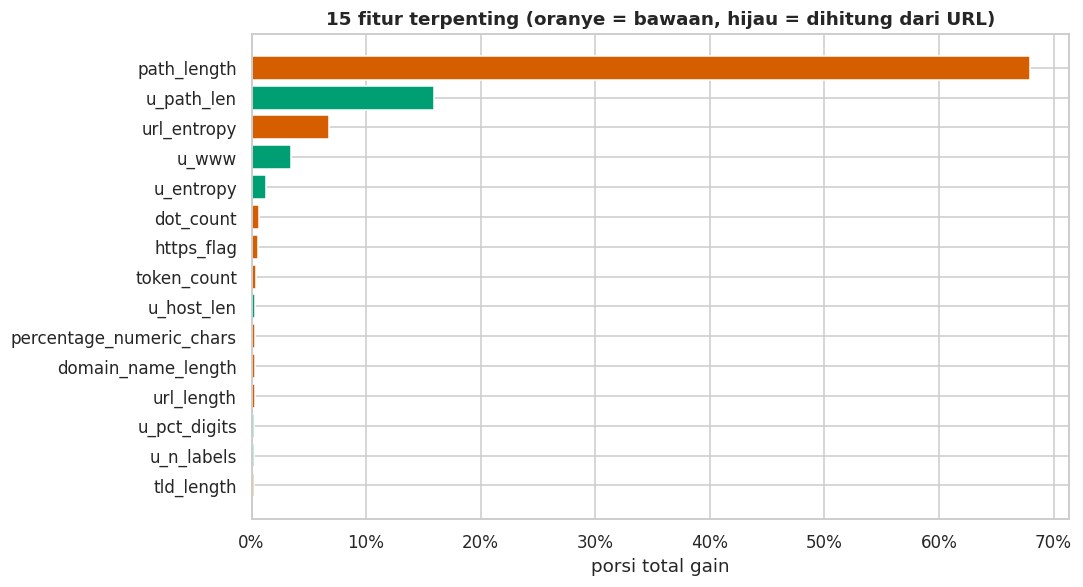

Porsi gain fitur bawaan: 78%


In [13]:
imp_model = lgb_model(0).fit(X_both, y)
imp = pd.Series(imp_model.booster_.feature_importance("gain"), index=X_both.columns)
imp = (imp / imp.sum()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(imp.index, imp.values, color=[C2 if c in PROVIDED else C3 for c in imp.index])
pct_axis(ax, 0, axis="x"); ax.set(xlabel="porsi total gain", title="15 fitur terpenting (oranye = bawaan, hijau = dihitung dari URL)")
save_fig(FIG_DIR, "05_importance")
print(f"Porsi gain fitur bawaan: {imp_model.booster_.feature_importance('gain')[:len(PROVIDED)].sum() / imp_model.booster_.feature_importance('gain').sum():.0%}")

**Temuan.** Panjang path mendominasi: versi bawaan menyumbang 68% gain dan versi yang dihitung ulang 16%. Keduanya dipakai bersama karena versi bawaan berisi noise di 14% baris, dan model memakai versi bersih untuk mengoreksinya. Berikutnya entropi bawaan (7%), penanda `www` (3%), dan entropi asli. Fitur bawaan secara total menyumbang 78% gain. Jadi pertanyaan utama model adalah "apakah URL ini punya path?", yang sama dengan membedakan beranda dari URL lain.

### 7.2 Di mana model salah?

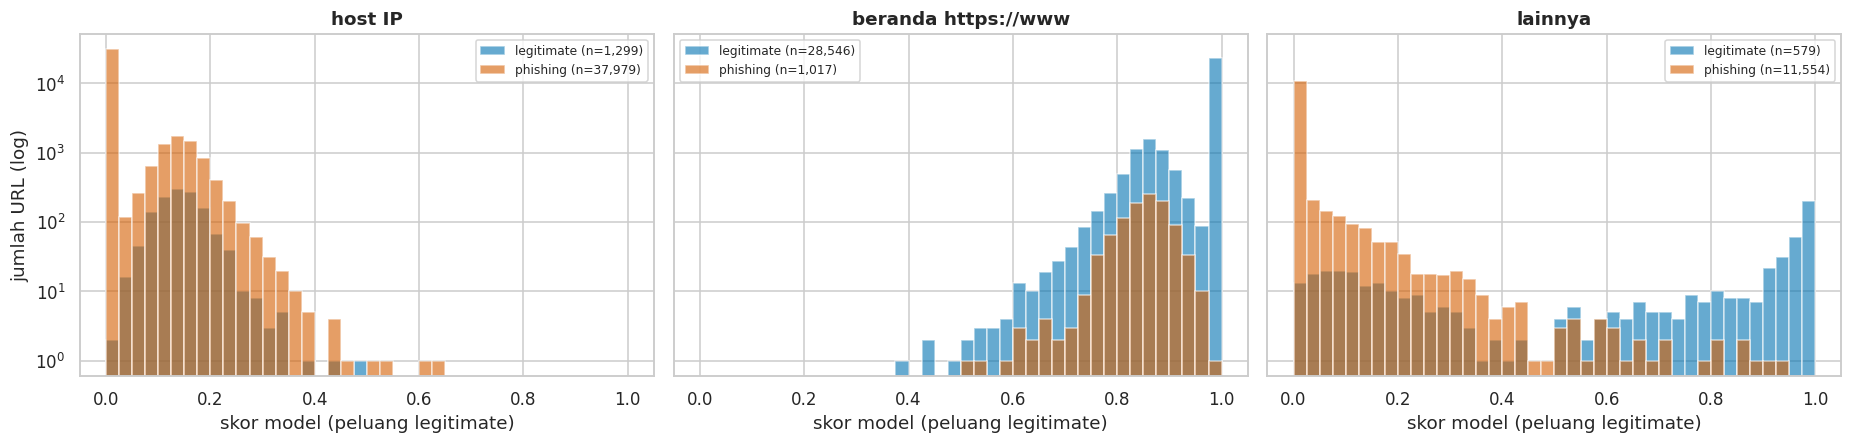

,URL,tipe,label,skor
15340,https://www.christianchurchsupply.com,beranda https://www,0,0.999247
55181,https://support.google.com/chrome/answer/26937...,lainnya,1,0.001027
73658,http://5000best.com/websites,lainnya,1,0.001606
77674,http://5000best.com/websites,lainnya,1,0.001766
21413,http://www.kelloggs.com/en_US/home.html,lainnya,1,0.005657
75499,https://geek.digit.in/community/threads/most-f...,lainnya,1,0.006289
66628,http://web.archive.org/,lainnya,1,0.008649
40874,www.gttconnect.com.cn/reg/d/www.paypal.fr/Pay_...,lainnya,1,0.009595
15505,http://tools.kali.pro.s3.amazonaws.com/jbossas...,lainnya,1,0.009750
6847,http://sumerda.com/projects/useraccount.aspx,lainnya,1,0.011548


In [14]:
p_fin = OOF[FINAL_NAME]
err = pd.DataFrame({"URL": train.URL, "tipe": TYPE_TR, "label": y, "skor": p_fin})
err["salah"] = (err.skor > 0.5).astype(int) != err.label
by = err.groupby(["tipe", "label"]).agg(baris=("skor", "size"), salah=("salah", "mean"), skor_median=("skor", "median"))
by["porsi seluruh kesalahan"] = err.groupby(["tipe", "label"]).salah.sum() / err.salah.sum()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for a, tp in zip(axes, ORDER):
    for k, col, lab in [(1, C1, "legitimate"), (0, C2, "phishing")]:
        s = err.skor[(err.tipe == tp) & (err.label == k)]
        a.hist(s, bins=np.linspace(0, 1, 41), color=col, alpha=0.6, label=f"{lab} (n={len(s):,})", log=True)
    a.set(title=tp, xlabel="skor model (peluang legitimate)"); a.legend(fontsize=8)
axes[0].set_ylabel("jumlah URL (log)")
save_fig(FIG_DIR, "06_errors")
display(by.style.format({"baris": "{:,.0f}", "salah": "{:.1%}", "skor_median": "{:.3f}", "porsi seluruh kesalahan": "{:.0%}"}))
worst = err.assign(loss=np.abs(err.label - err.skor)).sort_values("loss", ascending=False)
worst.head(15)[["URL", "tipe", "label", "skor"]]

**Temuan.** Pada ambang 0,5, **semua** host IP berlabel legitimate dan semua beranda berlabel phishing diprediksi salah, dan dua kelompok ini memuat 92% seluruh kesalahan. Model memberi skor yang sesuai dengan bentuk URL-nya (median 0,145 untuk host IP berlabel legitimate, 0,859 untuk beranda berlabel phishing), dan menurut kami di sinilah model benar dan labelnya yang keliru. Kelompok ketiga adalah URL legitimate yang bukan beranda (579 URL, 28,8% salah), misalnya `support.google.com/chrome/answer/...` atau `web.archive.org`. Ini kelemahan nyata: karena hampir semua URL legitimate di data latih adalah beranda, model belajar bahwa URL dengan path itu mencurigakan. Di dunia nyata, model ini akan menandai banyak tautan sah ke halaman dalam situs.

## 8. Submission

Model akhir dilatih ulang pada seluruh data latih. Untuk LightGBM, prediksi dirata-rata dari 3 seed.

In [15]:
X_te = {"LightGBM, fitur bawaan": test[PROVIDED], "LightGBM, bawaan + bersih": pd.concat([test[PROVIDED], CLEAN_TE], axis=1),
        "LightGBM, bawaan + bersih + penanda": pd.concat([test[PROVIDED], CLEAN_TE, MIS_TE], axis=1)}
X_trn = {"LightGBM, fitur bawaan": X_prov, "LightGBM, bawaan + bersih": X_both, "LightGBM, bawaan + bersih + penanda": X_all}
key = FINAL_NAME if FINAL_NAME in X_te else "LightGBM, bawaan + bersih"
p_lgb = np.mean([lgb_model(s).fit(X_trn[key], y).predict_proba(X_te[key])[:, 1] for s in SEEDS], axis=0)
if FINAL_NAME.startswith("rata-rata"):
    p_txt = tfidf_model(0).fit(train.URL, y).predict_proba(test.URL)[:, 1]
    p_test = rank_mean(p_lgb, p_txt)
else:
    p_test = p_lgb
target_col = sample.columns[1]
sub = sample[[ID]].merge(pd.DataFrame({ID: test[ID], target_col: p_test}), on=ID, how="left")
assert sub[target_col].notna().all() and len(sub) == len(sample)
sub.to_csv(OUT_DIR / "submission.csv", index=False)
res.to_csv(OUT_DIR / "cv_results.csv"); by.to_csv(OUT_DIR / "errors_by_type.csv")
print(f"Model: {FINAL_NAME} | proporsi skor > 0,5 di test: {(p_test > 0.5).mean():.1%} (train legit {y.mean():.1%})")

Model: LightGBM, bawaan + bersih | proporsi skor > 0,5 di test: 37.1% (train legit 37.6%)


**Temuan.** Proporsi skor di atas 0,5 di test (37,1%) sama dengan proporsi legitimate di train (37,6%).

## 9. Kesimpulan

1. **AUC 0,99 sebagian besar berasal dari struktur dataset.** Beranda `https://www` hampir selalu legitimate dan host IP hampir selalu phishing; aturan satu baris sudah memberi AUC 0,959.
2. **Sisa error didominasi label yang tampak keliru.** 92% kesalahan ada di dua kelompok yang labelnya berlawanan dengan isi URL. Model yang lebih kuat tidak akan banyak membantu di sini.
3. **Fitur yang diubah ikut membawa informasi.** Fitur bawaan yang disisipi noise memberi AUC lebih tinggi daripada fitur bersih dari URL (0,9931 vs 0,9876). Untuk kompetisi, keduanya dipakai; untuk sistem sungguhan, model fitur bersih (0,9876) adalah gambaran yang lebih jujur.
4. **Hasil.** Late submission private 0,99390, di atas submission tim saat kompetisi (0,99378) dan 0,0002 di bawah peringkat 1.

**Keterbatasan.** Kelas legitimate hampir seluruhnya beranda, sehingga model tidak belajar membedakan halaman dalam situs yang sah dari halaman phishing. Evaluasi pada URL dunia nyata yang lebih beragam akan menghasilkan skor yang jauh lebih rendah.

### Jejak lingkungan

In [16]:
import platform
pkgs = ["numpy", "pandas", "scikit-learn", "lightgbm", "matplotlib", "seaborn"]
print(" | ".join([f"python {platform.python_version()}"] + [f"{p} {version(p)}" for p in pkgs]))
print(f"Waktu eksekusi total: {(time.time() - T0) / 60:.1f} menit")

python 3.13.18 | numpy 2.1.3 | pandas 2.3.3 | scikit-learn 1.6.1 | lightgbm 4.6.0 | matplotlib 3.10.0 | seaborn 0.13.2
Waktu eksekusi total: 8.7 menit
